# Structural Damage Classification

## 1. Prep

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from catboost import CatBoostClassifier

ROOT = Path.cwd()
print("Working directory:", ROOT)
print("Pandas:", pd.__version__)

Working directory: c:\Users\HP\Documents\structural-damage-classification
Pandas: 3.0.6


## 2. Memuat data

In [3]:
train = pd.read_csv(ROOT / 'train.csv', dtype={'building_id': str})
test = pd.read_csv(ROOT / 'test.csv', dtype={'building_id': str})
sample = pd.read_csv(ROOT / 'sample_submission.csv', dtype={'building_id': str})
metadata = pd.read_csv(ROOT / 'metadata.csv')
print('Train:', train.shape, '| Test:', test.shape, '| Sample:', sample.shape)
display(train.head(3))
display(metadata.head(8))

Train: (533465, 17) | Test: (228629, 16) | Sample: (228629, 2)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone


,Variable,Description,Type
0,building_id,A unique ID that identifies a unique building ...,Text
1,district_id,District where the building is located,Text
2,vdcmun_id,Municipality where the building is located,Text
3,ward_id,Ward Number in which the building is located,Text
4,count_floors_pre_eq,Number of floors that the building had before ...,Number
5,age_building,Age of the building (in years),Number
6,plinth_area_sq_ft,Plinth area of the building (in square feet),Number
7,height_ft_pre_eq,Height of the building before the earthquake (...,Number


## 3. EDA: kualitas data dan ketidakseimbangan kelas

Kolom train: ['building_id', 'district_id', 'vdcmun_id', 'ward_id', 'count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'damage_grade', 'superstructure']
Missing values train: 0
Missing values test: 0
Duplikat building_id train: 0
Duplikat building_id test: 0


,jumlah,persen
damage_grade,,
Grade 1,55170,10.34
Grade 2,61080,11.45
Grade 3,95488,17.90
Grade 4,128691,24.12
Grade 5,193036,36.19


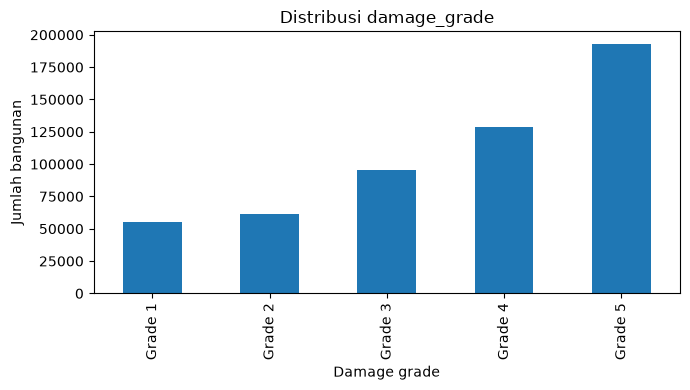

In [4]:
print('Kolom train:', train.columns.tolist())
print('Missing values train:', int(train.isna().sum().sum()))
print('Missing values test:', int(test.isna().sum().sum()))
print('Duplikat building_id train:', train['building_id'].duplicated().sum())
print('Duplikat building_id test:', test['building_id'].duplicated().sum())
counts = train['damage_grade'].value_counts().sort_index()
display(pd.DataFrame({'jumlah': counts, 'persen': (counts/counts.sum()*100).round(2)}))
ax = counts.plot(kind='bar', figsize=(7,4), title='Distribusi damage_grade')
ax.set_xlabel('Damage grade'); ax.set_ylabel('Jumlah bangunan')
plt.tight_layout(); plt.show()

## 4. Menentukan fitur dan tipe kategorikal

In [5]:
target = 'damage_grade'
features = [c for c in test.columns if c != 'building_id']
assert target in train.columns
assert all(c in train.columns for c in features)

cat_cols = [
    'district_id', 'vdcmun_id', 'ward_id',
    'land_surface_condition', 'foundation_type', 'roof_type',
    'ground_floor_type', 'other_floor_type', 'position',
    'plan_configuration', 'superstructure'
]
cat_cols = [c for c in cat_cols if c in features]
cat_cols += [c for c in features if (pd.api.types.is_object_dtype(train[c]) or pd.api.types.is_string_dtype(train[c])) and c not in cat_cols]
num_cols = [c for c in features if c not in cat_cols]

X = train[features].copy()
X_test = test[features].copy()
y = train[target].astype(str)

for c in cat_cols:
    X[c] = X[c].fillna('Missing').astype(str)
    X_test[c] = X_test[c].fillna('Missing').astype(str)
for c in num_cols:
    X[c] = pd.to_numeric(X[c], errors='raise')
    X_test[c] = pd.to_numeric(X_test[c], errors='raise')
    median = X[c].median()
    X[c] = X[c].fillna(median)
    X_test[c] = X_test[c].fillna(median)
print('Categorical:', cat_cols)
print('Numeric:', num_cols)
assert X.columns.equals(X_test.columns)
assert not X.isna().any().any() and not X_test.isna().any().any()

Categorical: ['district_id', 'vdcmun_id', 'ward_id', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'superstructure']
Numeric: ['count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']


## 5. Split train/validation (80/20 stratified)

In [6]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Training:', X_tr.shape, 'Validation:', X_val.shape)

Training: (426772, 15) Validation: (106693, 15)


## 6. Training CatBoost (baseline)

In [7]:
model = CatBoostClassifier(
    iterations=600,
    depth=7,
    learning_rate=0.06,
    loss_function='MultiClass',
    eval_metric='MultiClass',
    random_seed=42,
    verbose=100,
    thread_count=-1
)
model.fit(
    X_tr, y_tr,
    cat_features=cat_cols,
    eval_set=(X_val, y_val),
    early_stopping_rounds=70,
    use_best_model=True
)
print('Best iteration:', model.best_iteration_)

0:	learn: 1.5558478	test: 1.5558879	best: 1.5558879 (0)	total: 9.1s	remaining: 1h 30m 52s
100:	learn: 1.0489354	test: 1.0485012	best: 1.0485012 (100)	total: 13m 48s	remaining: 1h 8m 14s
200:	learn: 1.0249464	test: 1.0268290	best: 1.0268290 (200)	total: 28m 57s	remaining: 57m 47s
300:	learn: 1.0111448	test: 1.0156554	best: 1.0156554 (300)	total: 43m 57s	remaining: 43m 48s
400:	learn: 1.0034414	test: 1.0102551	best: 1.0102551 (400)	total: 58m 46s	remaining: 29m 14s
500:	learn: 0.9976722	test: 1.0065006	best: 1.0065006 (500)	total: 1h 12m 56s	remaining: 14m 26s
599:	learn: 0.9931391	test: 1.0038922	best: 1.0038922 (599)	total: 1h 26m 25s	remaining: 0us

bestTest = 1.003892175
bestIteration = 599

Best iteration: 599


## 7. Evaluasi Macro F1 dan confusion matrix

Validation Macro F1: 0.52847
              precision    recall  f1-score   support

     Grade 1     0.6074    0.7373    0.6660     11034
     Grade 2     0.4273    0.2812    0.3392     12216
     Grade 3     0.4166    0.4143    0.4155     19098
     Grade 4     0.5035    0.4828    0.4929     25738
     Grade 5     0.7026    0.7568    0.7287     38607

    accuracy                         0.5729    106693
   macro avg     0.5315    0.5345    0.5285    106693
weighted avg     0.5620    0.5729    0.5647    106693



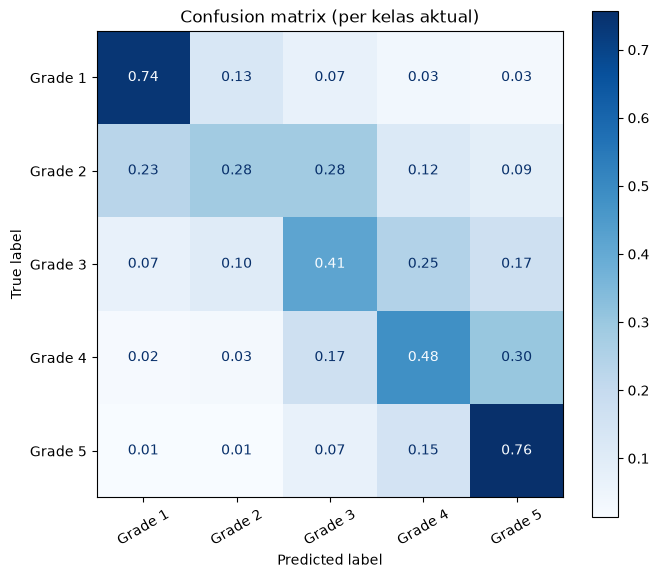

In [8]:
pred_val = np.asarray(model.predict(X_val)).reshape(-1)
score = f1_score(y_val, pred_val, average='macro')
print(f'Validation Macro F1: {score:.5f}')
print(classification_report(y_val, pred_val, digits=4, zero_division=0))
labels = sorted(y.unique())
fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, labels=labels,
    normalize='true', ax=ax, values_format='.2f', cmap='Blues')
plt.xticks(rotation=30); plt.title('Confusion matrix (per kelas aktual)')
plt.tight_layout(); plt.show()

## 8. Feature importance

,importance
ward_id,26.811404
vdcmun_id,21.616760
superstructure,10.087488
age_building,9.113088
district_id,4.787997
foundation_type,4.714752
other_floor_type,4.621254
ground_floor_type,3.463885
land_surface_condition,3.445922
plinth_area_sq_ft,3.213524


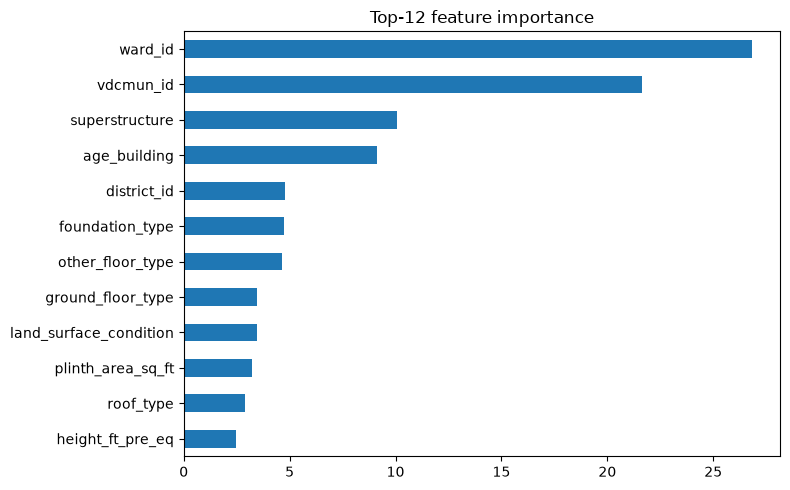

In [9]:
imp = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
display(imp.head(15).rename('importance').to_frame())
imp.head(12).sort_values().plot.barh(figsize=(8,5), title='Top-12 feature importance')
plt.tight_layout(); plt.show()

## 9. Latih final model pada seluruh data training

In [10]:
best_n = max(1, int(model.best_iteration_) + 1)
final_model = CatBoostClassifier(
    iterations=best_n, depth=7, learning_rate=0.06,
    loss_function='MultiClass', random_seed=42, verbose=100,
    thread_count=-1
)
final_model.fit(X, y, cat_features=cat_cols)
print('Final model fitted with', best_n, 'iterations')

0:	learn: 1.5558327	total: 7.75s	remaining: 1h 17m 19s
100:	learn: 1.0488529	total: 15m 32s	remaining: 1h 16m 45s
200:	learn: 1.0251291	total: 32m 22s	remaining: 1h 4m 16s
300:	learn: 1.0125372	total: 49m 57s	remaining: 49m 37s
400:	learn: 1.0044773	total: 1h 8m 15s	remaining: 33m 52s
500:	learn: 0.9991503	total: 1h 24m 52s	remaining: 16m 46s
599:	learn: 0.9945509	total: 1h 41m 4s	remaining: 0us
Final model fitted with 600 iterations


## 10. Prediksi test dan buat submission

In [11]:
pred_test = np.asarray(final_model.predict(X_test)).reshape(-1).astype(str)
submission = pd.DataFrame({
    'building_id': test['building_id'],
    'damage_grade': pred_test
})
assert list(submission.columns) == ['building_id', 'damage_grade']
assert len(submission) == len(test)
assert submission['building_id'].equals(test['building_id'])
assert set(submission['damage_grade']).issubset({f'Grade {i}' for i in range(1,6)})
assert set(sample.columns) == set(submission.columns)
assert sample['building_id'].equals(submission['building_id']), 'Periksa urutan building_id pada sample_submission!'
output_path = ROOT / 'submission_catboost.csv'
submission.to_csv(output_path, index=False)
print('Disimpan:', output_path)
print('Shape:', submission.shape)
display(submission.head())
print('Prediksi tiap kelas:')
print(submission['damage_grade'].value_counts().sort_index())

Disimpan: c:\Users\HP\Documents\structural-damage-classification\submission_catboost.csv
Shape: (228629, 2)


,building_id,damage_grade
0,122207000141,Grade 2
1,284909000871,Grade 5
2,241904000231,Grade 4
3,248308000891,Grade 3
4,300405002981,Grade 5


Prediksi tiap kelas:
damage_grade
Grade 1    28724
Grade 2    17509
Grade 3    40035
Grade 4    52380
Grade 5    89981
Name: count, dtype: int64


In [12]:

import pandas as pd
from pathlib import Path

# Lokasi file submission sebelumnya
file_lama = Path("submission_catboost.csv")

# Baca hasil prediksi
submission = pd.read_csv(
    file_lama,
    dtype={"building_id": str}
)

# Ubah "Grade 1" menjadi 1, dst.
submission["damage_grade"] = (
    submission["damage_grade"]
    .astype(str)
    .str.strip()
    .str.replace(r"^Grade\s+", "", regex=True)
    .astype(int)
)

# Validasi sebelum disimpan
assert submission["damage_grade"].isin([1, 2, 3, 4, 5]).all()
assert len(submission) == 228629
assert submission["building_id"].is_unique

# Simpan file baru
submission.to_csv(
    "submission_catboost1.csv",
    index=False
)

print("Submission berhasil diperbaiki!")
print(submission.head())
print(submission.dtypes)


Submission berhasil diperbaiki!
    building_id  damage_grade
0  122207000141             2
1  284909000871             5
2  241904000231             4
3  248308000891             3
4  300405002981             5
building_id       str
damage_grade    int64
dtype: object
